# Chapter 10: Many Variables at Once

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 10.1 Many Columns in One Picture

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('book.mplstyle')

customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])

In [2]:
customers['cancelled'] = customers['customer_id'].isin(
    cancellations['customer_id'])
cancel_dates = cancellations.set_index('customer_id')['cancel_date']
data_end = pd.Timestamp('2025-12-31')
end_date = customers['customer_id'].map(cancel_dates).fillna(data_end)
days = (end_date - customers['signup_date']).dt.days
customers['tenure_months'] = (days / 30.44).round(1)

spend = orders.groupby('customer_id')['amount'].sum()
order_count = orders.groupby('customer_id').size()
customers['total_spend'] = customers['customer_id'].map(spend)
customers['orders'] = customers['customer_id'].map(order_count)
customers[['customer_id', 'plan', 'cancelled', 'tenure_months',
           'total_spend', 'orders']].head()

,customer_id,plan,cancelled,tenure_months,total_spend,orders
0,1001,Basic,False,24.0,435.37,26
1,1002,Basic,True,0.2,8.00,1
2,1003,Standard,True,15.8,479.02,19
3,1004,Basic,True,0.8,8.00,1
4,1005,Basic,True,3.3,56.00,4


### `sns.pairplot()`

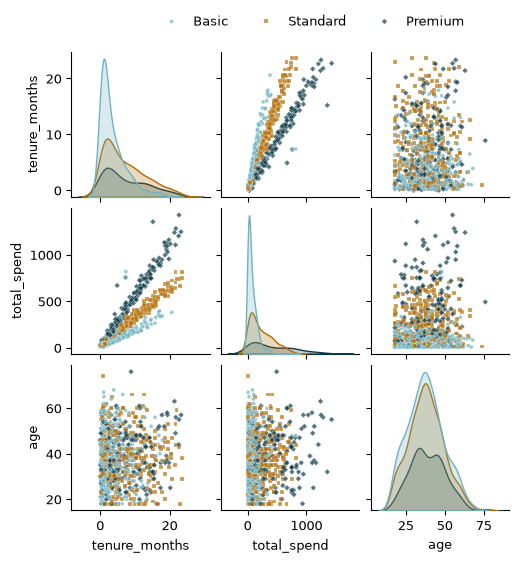

In [3]:
plan_order = ['Basic', 'Standard', 'Premium']
plan_colors = ['#6fb3c2', '#b26a00', '#0b3a47']
sample = customers.sample(1000, random_state=42)

g = sns.pairplot(data=sample,
                 vars=['tenure_months', 'total_spend', 'age'],
                 hue='plan', hue_order=plan_order,
                 palette=plan_colors, markers=['o', 's', 'D'],
                 height=1.75,
                 plot_kws={'alpha': 0.7, 's': 8})
sns.move_legend(g, 'lower center', bbox_to_anchor=(0.5, 1),
                ncols=3, title=None, frameon=False)
plt.show()

## 10.2 Small Multiples

### `sns.relplot()`

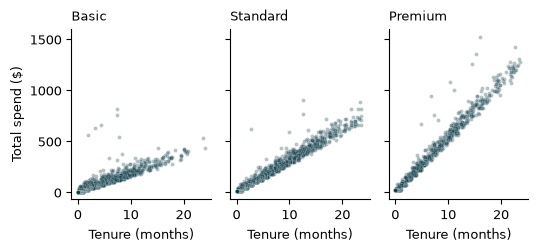

In [4]:
g = sns.relplot(data=customers, x='tenure_months', y='total_spend',
                col='plan', col_order=plan_order, color='#0b3a47',
                alpha=0.3, s=8, height=2.6, aspect=0.7)
g.set_titles('{col_name}')
g.set_axis_labels('Tenure (months)', 'Total spend ($)')
plt.show()

## 10.3 Simpson's Paradox

In [5]:
two_channels = customers[customers['channel'].isin(
    ['Podcast', 'Search'])]
two_channels.groupby('channel').agg(
    customers=('cancelled', 'count'),
    cancel_rate=('cancelled', 'mean')).round(3)

,customers,cancel_rate
channel,,
Podcast,678,0.624
Search,1472,0.539


### Splitting by plan

In [6]:
rates = two_channels.pivot_table(
    values='cancelled', index='plan', columns='channel',
    aggfunc='mean').loc[plan_order]
rates.round(3)

channel,Podcast,Search
plan,,
Basic,0.665,0.711
Standard,0.356,0.519
Premium,0.286,0.362


In [7]:
two_channels.pivot_table(
    values='cancelled', index='plan', columns='channel',
    aggfunc='count').loc[plan_order]

channel,Podcast,Search
plan,,
Basic,591,477
Standard,73,603
Premium,14,392


### The plan mix explains it

In [8]:
mix = pd.crosstab(two_channels['channel'], two_channels['plan'],
                  normalize='index')[plan_order]
mix.round(3)

plan,Basic,Standard,Premium
channel,,,
Podcast,0.872,0.108,0.021
Search,0.324,0.410,0.266


In [9]:
podcast_own = np.average(rates['Podcast'], weights=mix.loc['Podcast'])
search_own = np.average(rates['Search'], weights=mix.loc['Search'])
print(f'Podcast, own plan mix: {podcast_own:.1%}')
print(f'Search, own plan mix:  {search_own:.1%}')

Podcast, own plan mix: 62.4%
Search, own plan mix:  53.9%


In [10]:
podcast_search_mix = np.average(rates['Podcast'],
                                weights=mix.loc['Search'])
print(f'Podcast, with the Search plan mix: {podcast_search_mix:.1%}')
print(f'Search, as it is:                  {search_own:.1%}')

Podcast, with the Search plan mix: 43.7%
Search, as it is:                  53.9%


### A chart that shows the reversal

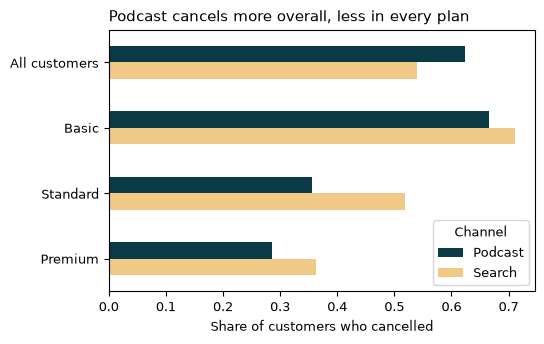

In [11]:
reversal = two_channels.pivot_table(
    values='cancelled', index='plan', columns='channel',
    aggfunc='mean', margins=True, margins_name='All customers')
reversal = reversal.loc[['All customers'] + plan_order,
                        ['Podcast', 'Search']]

ax = reversal.plot.barh(color=['#0b3a47', '#f0c987'])
ax.invert_yaxis()
ax.set_title('Podcast cancels more overall, less in every plan')
ax.set_xlabel('Share of customers who cancelled')
ax.set_ylabel('')
ax.legend(title='Channel')
plt.show()

## 10.4 Splitting Further

### Three keys in `groupby()`

In [12]:
by_three = two_channels.groupby(['plan', 'device', 'channel']).agg(
    customers=('cancelled', 'count'),
    cancel_rate=('cancelled', 'mean'))
by_three.round(3)

customers  cancel_rate
plan     device  channel                        
Basic    Desktop Podcast        211        0.687
                 Search         178        0.685
         Mobile  Podcast        380        0.653
                 Search         299        0.726
Premium  Desktop Podcast          5        0.400
                 Search         152        0.388
         Mobile  Podcast          9        0.222
                 Search         240        0.346
Standard Desktop Podcast         33        0.364
                 Search         225        0.511
         Mobile  Podcast         40        0.350
                 Search         378        0.524

### Three keys in `pivot_table()`

In [13]:
three_grid = two_channels.pivot_table(
    values='cancelled', index=['plan', 'device'], columns='channel',
    aggfunc=['mean', 'count'])
three_grid.loc[plan_order].round(3)

mean          count       
channel          Podcast Search Podcast Search
plan     device                               
Basic    Desktop   0.687  0.685     211    178
         Mobile    0.653  0.726     380    299
Standard Desktop   0.364  0.511      33    225
         Mobile    0.350  0.524      40    378
Premium  Desktop   0.400  0.388       5    152
         Mobile    0.222  0.346       9    240

### `sns.catplot()`

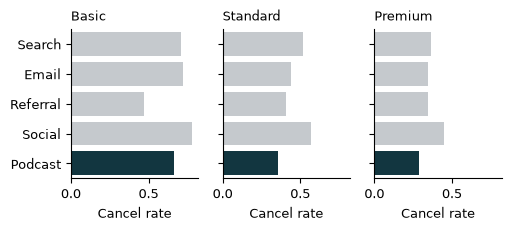

In [14]:
channel_order = ['Search', 'Email', 'Referral', 'Social', 'Podcast']
highlight = {channel: '#c4c9ce' for channel in channel_order}
highlight['Podcast'] = '#0b3a47'

g = sns.catplot(data=customers, kind='bar', x='cancelled',
                y='channel', order=channel_order, hue='channel',
                palette=highlight, legend=False, col='plan',
                col_order=plan_order, errorbar=None,
                height=2.4, aspect=0.75)
g.set_titles('{col_name}')
g.set_axis_labels('Cancel rate', '')
plt.show()

## 10.5 Customer Segments with RFM

### The three numbers

In [15]:
last_order = orders.groupby('customer_id')['order_date'].max()
rfm = customers[['customer_id', 'plan', 'cancelled']].copy()
rfm['recency'] = (data_end
                  - rfm['customer_id'].map(last_order)).dt.days
rfm['frequency'] = customers['orders']
rfm['monetary'] = customers['total_spend']
rfm[['recency', 'frequency', 'monetary']].describe().round(1)

,recency,frequency,monetary
count,4210.0,4210.0,4210.0
mean,170.6,6.8,184.1
std,196.9,6.3,227.1
min,0.0,1.0,8.0
25%,13.0,2.0,24.6
50%,64.5,5.0,95.4
75%,310.0,10.0,249.6
max,730.0,32.0,1527.2


### Scores with `pd.qcut()` and `rank(method='first')`

In [16]:
pd.qcut(rfm['frequency'], q=5).value_counts().sort_index()

frequency
(0.999, 2.0]    1339
(2.0, 3.0]       411
(3.0, 6.0]       846
(6.0, 12.0]      872
(12.0, 32.0]     742
Name: count, dtype: int64

In [17]:
frequency_rank = rfm['frequency'].rank(method='first')
pd.qcut(frequency_rank, q=5).value_counts().sort_index()

frequency
(0.999, 842.8]      842
(842.8, 1684.6]     842
(1684.6, 2526.4]    842
(2526.4, 3368.2]    842
(3368.2, 4210.0]    842
Name: count, dtype: int64

In [18]:
frequency_group = pd.qcut(frequency_rank, q=5,
                          labels=[1, 2, 3, 4, 5])
pd.crosstab(rfm['frequency'], frequency_group.rename('group')).head(3)

group,1,2,3,4,5
frequency,,,,,
1,798,0,0,0,0
2,44,497,0,0,0
3,0,345,66,0,0


In [19]:
up = [1, 2, 3, 4, 5]
down = [5, 4, 3, 2, 1]
rfm['R'] = pd.qcut(rfm['recency'].rank(method='first'), q=5,
                   labels=down).astype(int)
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5,
                   labels=up).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'].rank(method='first'), q=5,
                   labels=up).astype(int)
rfm[['customer_id', 'recency', 'frequency', 'monetary',
     'R', 'F', 'M']].head()

,customer_id,recency,frequency,monetary,R,F,M
0,1001,30,26,435.37,3,5,5
1,1002,730,1,8.00,1,1,1
2,1003,274,19,479.02,2,5,5
3,1004,729,1,8.00,1,1,1
4,1005,638,4,56.00,1,3,2


### From scores to segments

In [20]:
r, f, m = rfm['R'], rfm['F'], rfm['M']
rfm['segment'] = 'Needs attention'
rfm.loc[(r <= 2) & (f <= 2), 'segment'] = 'Lost'
rfm.loc[(r <= 2) & (f >= 3), 'segment'] = 'At risk'
rfm.loc[(r >= 4) & (f <= 2), 'segment'] = 'New'
rfm.loc[(r >= 3) & (f >= 3), 'segment'] = 'Loyal'
rfm.loc[(r >= 4) & (f >= 4) & (m >= 4), 'segment'] = 'Champions'
rfm['segment'].value_counts()

segment
Loyal              937
Lost               914
Champions          819
At risk            770
New                449
Needs attention    321
Name: count, dtype: int64

### What each segment looks like

In [21]:
segment_order = ['Champions', 'Loyal', 'New', 'Needs attention',
                 'At risk', 'Lost']
profile = rfm.groupby('segment').agg(
    customers=('customer_id', 'count'),
    days_since=('recency', 'median'),
    orders=('frequency', 'median'),
    spend=('monetary', 'median'),
    cancel_rate=('cancelled', 'mean'),
    revenue=('monetary', 'sum'))
profile['revenue'] = profile['revenue'] / profile['revenue'].sum()
profile.loc[segment_order].round(2)

,customers,days_since,orders,spend,cancel_rate,revenue
segment,,,,,,
Champions,819,11.0,14.0,395.62,0.03,0.49
Loyal,937,26.0,6.0,131.25,0.41,0.25
New,449,10.0,2.0,24.50,0.06,0.02
Needs attention,321,68.0,2.0,24.00,0.77,0.01
At risk,770,319.0,7.0,154.00,1.00,0.20
Lost,914,396.0,1.5,24.00,1.00,0.03


In [22]:
rfm['segment'] = rfm['segment'].replace({'At risk': 'Win back'})
segment_order[4] = 'Win back'
profile = profile.rename(index={'At risk': 'Win back'})

### Customers against revenue

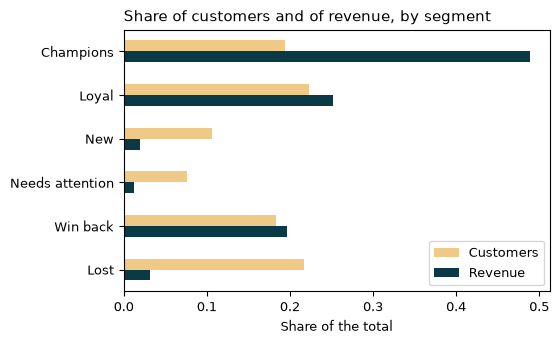

In [23]:
shares = pd.DataFrame({
    'Customers': profile['customers'] / profile['customers'].sum(),
    'Revenue': profile['revenue']}).loc[segment_order]

ax = shares.plot.barh(color=['#f0c987', '#0b3a47'])
ax.invert_yaxis()
ax.set_title('Share of customers and of revenue, by segment')
ax.set_xlabel('Share of the total')
ax.set_ylabel('')
plt.show()

### Keep RFM honest

In [24]:
rfm.groupby('R')['cancelled'].mean().round(3)

R
1    1.000
2    1.000
3    0.723
4    0.068
5    0.023
Name: cancelled, dtype: float64